<a href="https://colab.research.google.com/github/192565074simats-code/MLA0201/blob/main/Experiment_20.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

TRAINING DATASET
    Month  Advertising_Cost  Discount  Previous_Sales  Sales
0       1              1000         5             100    105
1       2              1200        10             110    115
2       3              1100         5             105    110
3       4              1500        10             120    125
4       5              1300         5             115    120
5       6              1600        15             130    140
6       7              1700        10             140    145
7       8              1800         5             135    150
8       9              1500        10             145    148
9      10              2000        15             155    165
10     11              2100        10             160    170
11     12              2200         5             170    175
12     13              2300        10             175    185
13     14              2400        15             180    190
14     15              2200         5             185    195
15     

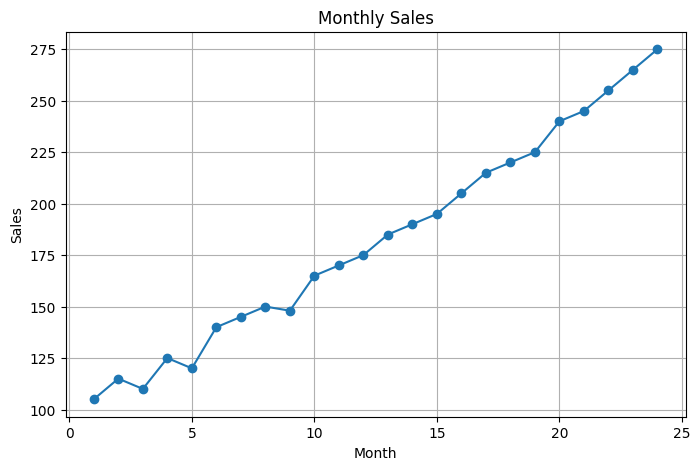

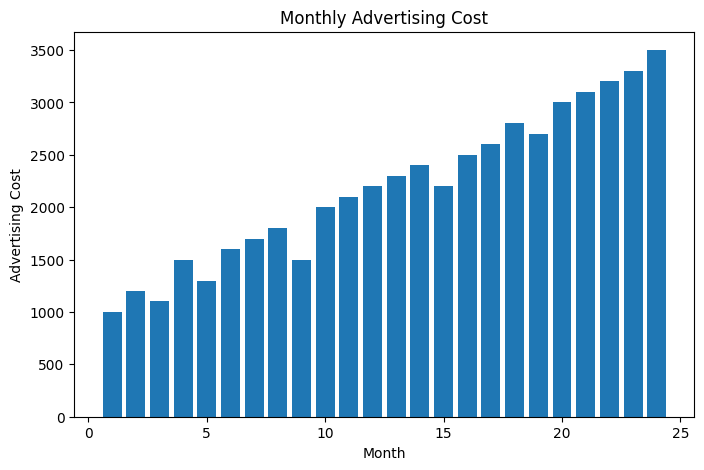

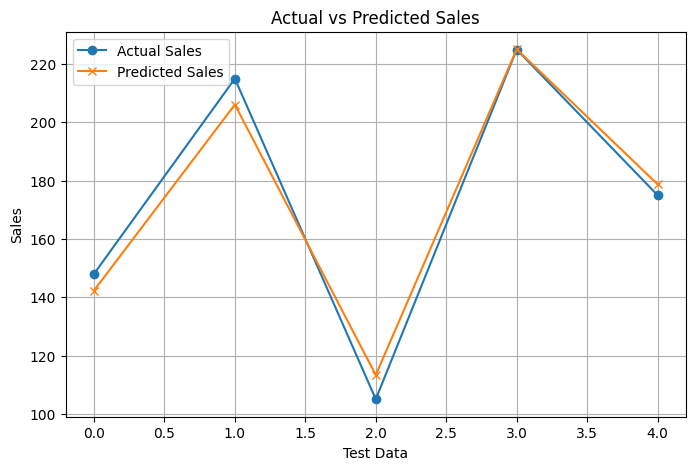

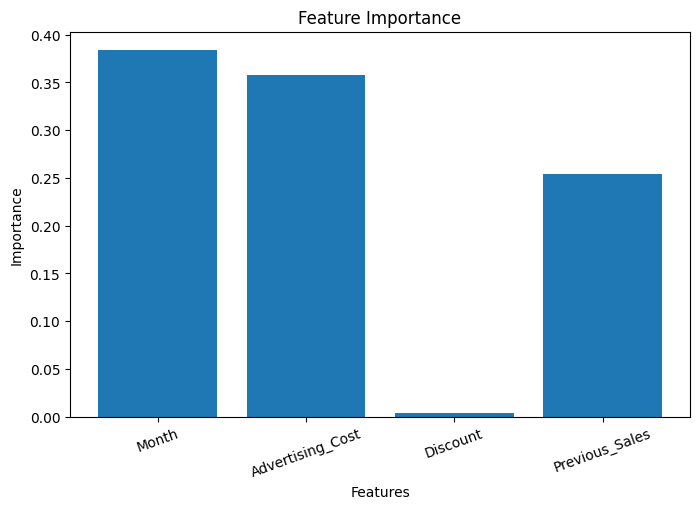


FUTURE SALES PREDICTION
Future Month: 25
Predicted Sales: 267.65


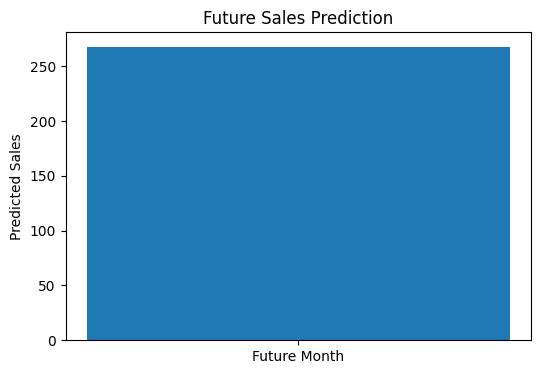

In [1]:
# EXPERIMENT 20
# FUTURE SALES PREDICTION USING RANDOM FOREST REGRESSION

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. CREATE TRAINING DATASET

data = {
    'Month': list(range(1, 25)),
    'Advertising_Cost': [
        1000, 1200, 1100, 1500, 1300, 1600,
        1700, 1800, 1500, 2000, 2100, 2200,
        2300, 2400, 2200, 2500, 2600, 2800,
        2700, 3000, 3100, 3200, 3300, 3500
    ],
    'Discount': [
        5, 10, 5, 10, 5, 15, 10, 5,
        10, 15, 10, 5, 10, 15, 5, 10,
        15, 10, 5, 15, 10, 5, 15, 10
    ],
    'Previous_Sales': [
        100, 110, 105, 120, 115, 130,
        140, 135, 145, 155, 160, 170,
        175, 180, 185, 195, 200, 210,
        215, 225, 230, 240, 250, 260
    ],
    'Sales': [
        105, 115, 110, 125, 120, 140,
        145, 150, 148, 165, 170, 175,
        185, 190, 195, 205, 215, 220,
        225, 240, 245, 255, 265, 275
    ]
}

df = pd.DataFrame(data)

print("TRAINING DATASET")
print(df)

# 2. INPUT AND OUTPUT

X = df[['Month', 'Advertising_Cost',
        'Discount', 'Previous_Sales']]

y = df['Sales']

# 3. SPLIT DATASET

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 4. TRAIN RANDOM FOREST MODEL

model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

# 5. PREDICT TEST DATA

y_pred = model.predict(X_test)

print("\nACTUAL VS PREDICTED SALES")

result = pd.DataFrame({
    'Actual Sales': y_test.values,
    'Predicted Sales': np.round(y_pred, 2)
})

print(result)

# 6. MODEL EVALUATION

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\nMODEL PERFORMANCE")
print("Mean Absolute Error:", round(mae, 2))
print("Mean Squared Error:", round(mse, 2))
print("Root Mean Squared Error:", round(rmse, 2))
print("R2 Score:", round(r2, 2))

# 7. GRAPH - MONTHLY SALES

plt.figure(figsize=(8, 5))
plt.plot(df['Month'], df['Sales'], marker='o')
plt.title("Monthly Sales")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.grid()
plt.show()

# 8. GRAPH - ADVERTISING COST

plt.figure(figsize=(8, 5))
plt.bar(df['Month'], df['Advertising_Cost'])
plt.title("Monthly Advertising Cost")
plt.xlabel("Month")
plt.ylabel("Advertising Cost")
plt.show()

# 9. GRAPH - ACTUAL VS PREDICTED SALES

plt.figure(figsize=(8, 5))
plt.plot(y_test.values, label="Actual Sales", marker='o')
plt.plot(y_pred, label="Predicted Sales", marker='x')
plt.title("Actual vs Predicted Sales")
plt.xlabel("Test Data")
plt.ylabel("Sales")
plt.legend()
plt.grid()
plt.show()

# 10. FEATURE IMPORTANCE

importance = model.feature_importances_

plt.figure(figsize=(8, 5))
plt.bar(X.columns, importance)
plt.title("Feature Importance")
plt.xlabel("Features")
plt.ylabel("Importance")
plt.xticks(rotation=20)
plt.show()

# 11. FUTURE SALES PREDICTION

future_data = pd.DataFrame({
    'Month': [25],
    'Advertising_Cost': [3600],
    'Discount': [10],
    'Previous_Sales': [275]
})

future_prediction = model.predict(future_data)

print("\nFUTURE SALES PREDICTION")
print("Future Month:", 25)
print("Predicted Sales:", round(future_prediction[0], 2))

# 12. FUTURE SALES GRAPH

plt.figure(figsize=(6, 4))
plt.bar(['Future Month'], future_prediction)
plt.title("Future Sales Prediction")
plt.ylabel("Predicted Sales")
plt.show()